# Day 1: Upper Push

Trajectory + estimated-power analysis for this workout, built from what's logged in the app.

**Power (watts) is not measured** — the app only logs weight and reps, not time per rep. It's derived: `work = mass * g * range_of_motion * reps`, divided by an assumed time per rep (default 3s). Treat the watts number as a **relative trend**, not a lab-accurate figure. Tune `ROM_METERS` / `SEC_PER_REP` / bodyweight in `analysis_lib.py` if it feels off.

Run `../notebooks/pull_db.sh` first to refresh `data/workouts_snapshot.db` with the latest from the Pi.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))
import analysis_lib as lib

DAY = 1
WORKOUT_NAME = "Upper Push"

sessions, sets = lib.load_data(DAY)
sessions

,session_id,date,day,rpe,notes
0,1,2026-07-06,1,6,None
1,2,2026-07-13,1,6,None


## Logged sets

In [2]:
bodyweight = lib.get_latest_bodyweight()
print(f'Using bodyweight: {bodyweight} lbs (from /weight log, or default if none logged)')

sets = lib.add_volume(sets)
sets = lib.add_power(sets, bodyweight)
sets

Using bodyweight: 175.0 lbs (from /weight log, or default if none logged)


,session_id,date,exercise,set_number,weight,reps,reps_numeric,volume,power_w
0,1,2026-07-06,Dumbbell Bench Press,1,10.0,10,10,100.0,6.674606
1,1,2026-07-06,Dumbbell Bench Press,2,12.5,10,10,125.0,8.343258
2,1,2026-07-06,Dumbbell Bench Press,3,17.5,10,10,175.0,11.680561
3,1,2026-07-06,Dumbbell Bench Press,4,25.0,9,9,225.0,16.686516
4,1,2026-07-06,Dumbbell Overhead Press,1,20.0,8,8,160.0,13.349213
5,1,2026-07-06,Dumbbell Overhead Press,2,20.0,9,9,180.0,13.349213
6,1,2026-07-06,Dumbbell Overhead Press,3,17.5,8,8,140.0,11.680561
7,1,2026-07-06,Incline Dumbbell Press,1,20.0,9,9,180.0,11.865967
8,1,2026-07-06,Incline Dumbbell Press,2,15.0,11,11,165.0,8.899475
9,1,2026-07-06,Incline Dumbbell Press,3,15.0,12,12,180.0,8.899475


## Top-set weight trajectory

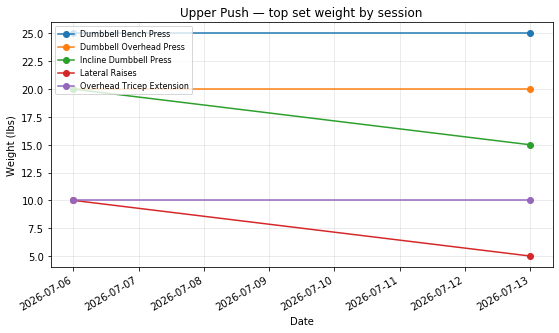

In [3]:
if not sets.empty:
    lib.plot_weight_trajectory(sets, WORKOUT_NAME)
else:
    print('No sessions logged for this day yet.')

## Volume and estimated power trajectory

,session_id,date,total_volume,avg_power_w
0,1,2026-07-06,2361.0,13.635561
1,2,2026-07-13,2367.5,14.127917


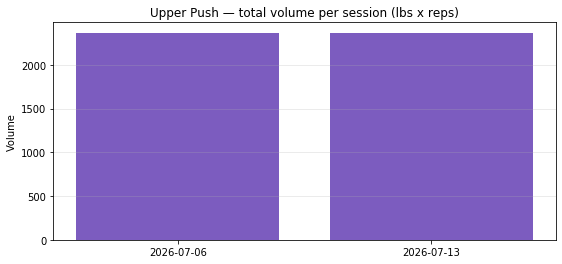

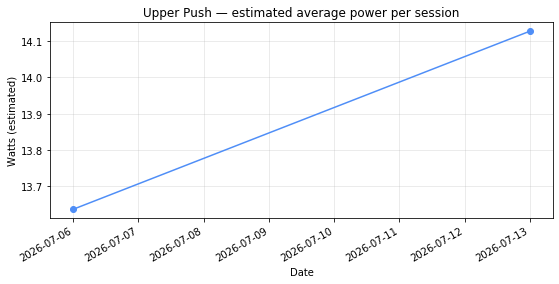

In [4]:
if not sets.empty:
    summary = lib.session_summary(sets)
    display(summary)
    lib.plot_volume_trajectory(summary, WORKOUT_NAME)
    lib.plot_power_trajectory(summary, WORKOUT_NAME)
else:
    print('No sessions logged for this day yet.')